In [1]:
import spacy
from nltk.corpus import stopwords
import re
import os
import unicodedata
from unidecode import unidecode
import pandas as pd
from spacy.tokens import Doc

In [2]:
import os
from dotenv import load_dotenv
from pathlib import Path

# Como o notebook está em 'corretor/src/3_avaliacao' e o .env em 'corretor',
# precisamos voltar duas pastas (../..) para achar o arquivo.
env_path = Path('../../.env')

# Carrega o arquivo explicitamente
load_dotenv(dotenv_path=env_path)

True

In [3]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\joaol\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [4]:
nlp = spacy.load("pt_core_news_lg")

In [5]:
PATH_BASE_TESTES_FINAIS = os.getenv('PATH_BASE_TESTES_FINAIS')
PATH_GABARITO_CORRETOR = os.getenv('PATH_GABARITO_CORRETOR')
PATH_BASE_ENTROPIA_SPACY = os.getenv('PATH_BASE_ENTROPIA_SPACY')

In [6]:
data = pd.read_csv(PATH_BASE_TESTES_FINAIS)

In [7]:
def preprocess(relato):
    def remove_stop_words(relato):
        sw = stopwords.words('portuguese')
        sw = [unidecode(word).upper() for word in sw]
        return ' '.join([token for token in re.split("[, ]", relato) if len(token) > 2 and token not in sw])
    
    def clean_relato(relato):
        relato = re.sub(r'\@(\w*\d?)', " ", relato)
        relato = re.sub(r'([A-z1-9]*_+[A-z1-9]*)|(_+[A-z1-9]*)|([A-z1-9]*_+)', " ", relato)
        relato = re.sub(r"((?:HTTPS?|WWW)(?:\:\/\/?)?[*a-zA-Z0-9\.\/\?\:@\-_=#]+[\.][a-zA-Z]{2,6}[a-zA-Z0-9\.\&\/\?\:@\-_=#]*)", " ", relato)
        relato = re.sub(r'(<[^<>]*>)|(&NBSP;)|(&nbsp;)', " ", relato)
        relato = re.sub(r"[^\w\s]", " ", relato)
        relato = re.sub(r"[\d]", " ", relato)
        relato = remove_stop_words(relato)
        return relato
    
    relato = clean_relato(relato)
    return relato

def normalize_text(text):
    if pd.isna(text):
        return text
    text = unicodedata.normalize('NFKD', text)
    text = ''.join(c for c in text if not unicodedata.combining(c))
    return text.upper()

In [8]:
data["relato_tratado"] = data["relato"].apply(normalize_text).apply(preprocess)

In [9]:
data['relato_tratado'][230]

'SUBJETIVO ADMISSAO DIABETES MELLITUS TIPO CENTRO DIABETES ENDOCRINOLOGIA DATA IDENTIFICACAO NOME CARMEN LUCIA GOMES IDADE DOMINANCIA MANUAL DESTRO CANHOTO AMBIDESTRO SEI ESCOLARIDADE ENSINO MEDIO COMPLETO TRABALHA SECRETARIA PROCEDENTE OSASCO PAULO EMAIL CARMEN GOMES HIPOTESES DIAGNOSTICAS DIABETES MELLITUS TIPO MAL CONTROLADA NECESSIDADE INTENSIFICACAO TRATAMENTO FARMACOLOGICO FARMACOLOGICO COMORBIDADES CLINICAS HIPERTENSAO ARTERIAL SISTEMICA HIPERCOLESTEROLEMIA COMORBIDADES NEUROLOGICAS PSIQUIATRICAS NEGA ANTECEDENTES HISTORIA FAMILIAR SIM SEI MAE IRMAO DOENCA RENAL CRONICA SIM SEI ESTAGIO RETINOPATIA DIABETICA SIM SEI GRAVIDADE NEUROPATIA PERIFERICA SIM SEI SENSITIVA MOTORA AUTONOMICA COMPLICACOES AGUDAS HISTORICO CETOACIDOSE DIABETICA ANOS MEDICACOES MEDICACOES ANTIDIABETICAS ATUAIS DOSES METFORMINA GLICLAZIDA INSULINA NPH TRATAMENTOS UTILIZADOS METFORMINA SULFONILUREIA GLICLAZIDA DPP INIBIDORES GLP ANALOGOS SGLT INIBIDORES INSULINA ACAO RAPIDA INSULINA BASAL NPH TIAZOLIDINEDIONAS

In [10]:
resultados = []

In [11]:
data['relato_tratado'] = data['relato_tratado'].str.lower()

In [12]:
for texto in data["relato_tratado"]:
    doc = nlp(texto)
    for token in doc:
        label = 1 if token.ent_type_ == "PER" else 0
        resultados.append((token.text, label))

In [13]:
df_resultado = pd.DataFrame(resultados, columns=["palavras", "label"])

In [14]:
df_resultado[df_resultado['label'] == 1]

,palavras,label
2,alice,1
3,moraes,1
66,paulo,1
67,sousa,1
68,matos,1
...,...,...
231782,crm,1
231784,jose,1
231785,alves,1
231788,mario,1


In [15]:
df_resultado['palavras'] = df_resultado['palavras'].str.upper()

In [16]:
df_resultado

,palavras,label
0,SUBJETIVO,0
1,NEFROLOGIA,0
2,ALICE,1
3,MORAES,1
4,ANOS,0
...,...,...
231793,BAIRRO,0
231794,BANCARIOS,0
231795,MORADOR,0
231796,RIO,0


In [17]:
df_resultado = df_resultado[df_resultado['palavras'] != '']
df_resultado


,palavras,label
0,SUBJETIVO,0
1,NEFROLOGIA,0
2,ALICE,1
3,MORAES,1
4,ANOS,0
...,...,...
231793,BAIRRO,0
231794,BANCARIOS,0
231795,MORADOR,0
231796,RIO,0


In [18]:
df = df_resultado.dropna(subset=['palavras'])

In [19]:
df['palavras'].iloc[[0]]

0    SUBJETIVO
Name: palavras, dtype: object

In [20]:
df

,palavras,label
0,SUBJETIVO,0
1,NEFROLOGIA,0
2,ALICE,1
3,MORAES,1
4,ANOS,0
...,...,...
231793,BAIRRO,0
231794,BANCARIOS,0
231795,MORADOR,0
231796,RIO,0


In [21]:
gab = pd.read_csv(PATH_GABARITO_CORRETOR)

In [22]:
test_output_list = df.copy()

In [23]:
teste2 = test_output_list.merge(gab[['palavra', 'y']], left_on='palavras', right_on='palavra', how='left')

teste2['y'] = teste2['y'].fillna(0).astype(int)

teste2.value_counts(subset=['y'])

y
0    211932
1     19866
Name: count, dtype: int64

In [24]:
teste2.dropna(subset=['palavra'])

,palavras,label,palavra,y
0,SUBJETIVO,0,SUBJETIVO,0
1,NEFROLOGIA,0,NEFROLOGIA,0
2,ALICE,1,ALICE,1
3,MORAES,1,MORAES,1
4,ANOS,0,ANOS,0
...,...,...,...,...
231793,BAIRRO,0,BAIRRO,0
231794,BANCARIOS,0,BANCARIOS,0
231795,MORADOR,0,MORADOR,0
231796,RIO,0,RIO,0


In [25]:
teste2 = teste2.dropna(subset=['palavra'])

In [26]:
teste2.value_counts(subset=['y'])

y
0    211932
1     19866
Name: count, dtype: int64

# metricas


In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

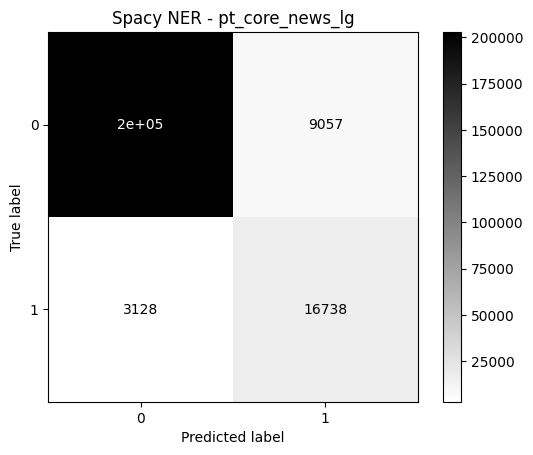

In [28]:
cm = confusion_matrix(teste2['y'], teste2['label'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap='binary')
plt.title("Spacy NER - pt_core_news_lg")
plt.show()

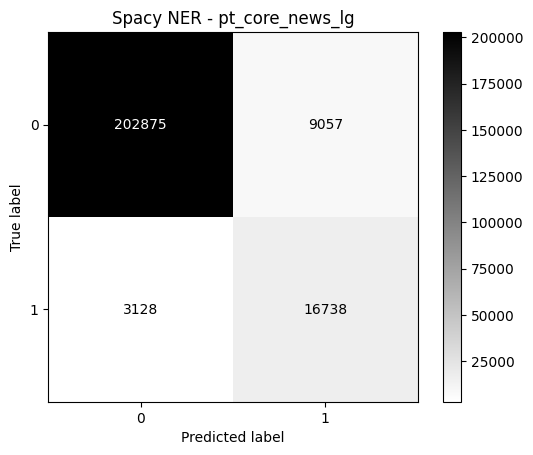

In [29]:
cm = confusion_matrix(teste2['y'], teste2['label'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap='binary', values_format='d')
plt.title("Spacy NER - pt_core_news_lg")
plt.show()

In [30]:
accuracy = accuracy_score(teste2['y'], teste2['label'])
accuracy

0.9474326784527908

In [31]:
precision = precision_score(teste2['y'], teste2['label'])
precision

np.float64(0.6488854429152937)

In [32]:
recall = recall_score(teste2['y'], teste2['label'])
recall

np.float64(0.8425450518473774)

In [33]:
f1 = f1_score(teste2['y'], teste2['label'])
f1

np.float64(0.7331420687238562)

# Anonimização

In [34]:
def anon_tokens(text, text_orig):
    resultados = []
    doc = nlp(text)
    for token in doc:
        label = 1 if token.ent_type_ == "PER" else 0
        resultados.append((token.text, label))
    # classified_tokens = classify_tokens(text)
    for palavra, label in resultados:
        if label == 1:
            text_orig = text_orig.replace(palavra.upper(), "***")
    return text_orig

In [35]:
anon_tokens(data["relato_tratado"][0], data["relato"][0])

'SUBJETIVO NEFROLOGIA 220 A - *** *** , 37 ANOS, PROFESSORA HORÁRIO : 08:10 RENAL : PACIENTE EM DIÁLISE PERITONEAL, SEM SINAIS DE PERITONITE. PERMEABILIDADE DE CATETER PRESERVADA. CRÉATININA ESTÁVEL 5,2 MG DL . HEMODINÂMICO : NORMOTENSO, SEM VARIAÇÕES SIGNIFICATIVAS DE PRESSÃO ARTERIAL PA 128 75 MMHG . FC EM RITMO REGULAR DE 82 BPM. RESPIRATÓRIO : SEM DISPNEIA OU OUTROS SINAIS DE SOBRECARGA HÍDRICA. AP : MURMÚRIOS VESICULARES PRESENTES E NORMAIS. ANEXOS : EDEMA 4 EM MEMBROS INFERIORES, PELE ÍNTEGRA E HIDRATADA, BOA COLORAÇÃO CUTÂNEA. CONDUTAS : MANTER DIÁLISE PERITONEAL CONFORME PRESCRIÇÃO. AJUSTE DE DIETA HIPO-SÓDICA. AVALIAÇÃO SEMANAL DE PARÂMETROS LABORATORIAIS E PESO SECO. ELABORADO E ASSINADO POR DR. *** *** *** , CRM 122345 EM 20 07 2022 16:18. CONTACTAR *** ATRAVÉS DO TELEFONE 11 98765-4321 OU E-MAIL ***.***@ESCOLA.*** . *** EM *** *** , SÃO *** . IDENTIFICADOR DO ATENDIMENTO 582734 .'

In [36]:
df_texts_anon = data.copy()

In [37]:
for index, row in df_texts_anon.iterrows():
    df_texts_anon.at[index, "relato_anon"] = anon_tokens(row["relato_tratado"], row["relato"])

In [38]:
df_texts_anon

,n_bop,relato,nomes,relato_tratado,relato_anon
0,1,"SUBJETIVO NEFROLOGIA 220 A - ALICE MORAES , 37...","ALICE, MORAES, PAULO, SOUSA, MATOS",subjetivo nefrologia alice moraes anos profess...,"SUBJETIVO NEFROLOGIA 220 A - *** *** , 37 ANOS..."
1,2,SUBJETIVO FISIOTERAPIA 402 A - RAFAELA MARTINS...,"RAFAELA, MARTINS, MARIA, SILVA, FERNANDO, CRUZ...",subjetivo fisioterapia rafaela martins anos de...,"SUBJETIVO FISIOTERAPIA 402 A - *** *** , 28 AN..."
2,3,SUBJETIVO CARDIOLOGIA 205 A - RICARDO GONÇALVE...,"RICARDO, GONÇALVES, ANDRÉ, FERNANDA, LIMA, OLI...",subjetivo cardiologia ricardo goncalves anos a...,"SUBJETIVO CARDIOLOGIA 205 A - *** GONÇALVES , ..."
3,4,SUBJETIVO GASTROENTEROLOGIA PACIENTE : PEDRO S...,"PEDRO, SANTOS, LUISA, FERNANDES",subjetivo gastroenterologia paciente pedro san...,SUBJETIVO GASTROENTEROLOGIA PACIENTE : *** ***...
4,5,"SUBJETIVO ORTOPEDIA 78 A - JOANA MARTINS , 52 ...","JOANA, MARTINS, RENATA, COSTA",subjetivo ortopedia joana martins anos profess...,"SUBJETIVO ORTOPEDIA 78 A - *** *** , 52 ANOS, ..."
...,...,...,...,...,...
1881,1882,SUBJETIVO UER - SALA LARANJA ID : CLÁUDIA SOAR...,"CLÁUDIA, SOARES, ALMEIDA, PEDRO, LARISSA, GOME...",subjetivo uer sala laranja claudia soares alme...,SUBJETIVO UER - SALA LARANJA ID : CLÁUDIA *** ...
1882,1883,SUBJETIVO UER - SALA AMARELA ID : RENATO AUGUS...,"RENATO, AUGUSTO, MOREIRA, FERNANDA, LOPES, SAM...",subjetivo uer sala amarela renato augusto more...,SUBJETIVO *** - SALA AMARELA ID : *** *** *** ...
1883,1884,SUBJETIVO UER - SALA AMARELA ID : GERTRUDES SI...,"GERTRUDES, SILVA, CARNEIRO, CLARISSA, DIEGO, H...",subjetivo uer sala amarela gertrudes silva car...,SUBJETIVO UER - SALA AMARELA ID : GERTRUDES SI...
1884,1885,SUBJETIVO CENTRO DE SAÚDE - CONSULTÓRIO ID : E...,"ELIANA, COSTA, SILVA, MARIANA, FREITAS, RAFAEL...",subjetivo centro saude consultorio eliana cost...,SUBJETIVO CENTRO DE SAÚDE - CONSULTÓRIO ID : *...


# entropy

In [39]:
import math
import numpy as np
import pandas as pd
from scipy.stats import entropy
from collections import Counter
import matplotlib.pyplot as plt
import scipy.stats as stats

É realizado o cálculo de entropia dos textos em claro e anonimizados, após isso realizada a comparação dos resultados obtidos.

- Foi criada uma tabela com o resultado da entropia de cada texto e realizada
- Realizado o cálculo da média de cada conjunto: Média dos resultados dos textos em claro e média dos resultados dos textos anonimizados. Assim podendo quantificar o impacto.
- Também foi realizado o cálculo do desvio padrão para mensurar diferença das entropias.

A entropia é calulada com base na probabilidade da ocorrência de cada caracter no texto. O resultado obtido da probabilidade de cada caracter é inserido para calculo da entropia utilizando a biblioteca entropy do scipy.stats que calcula a entropia com base na formula da entropia de shannon ( entropia da informação ).


In [40]:
def calculate_text_entropy(text, base=None):
    char_counts = Counter(text)
    total_chars = sum(char_counts.values())
    probabilities = np.array([count / total_chars for count in char_counts.values()])

    return entropy(probabilities, base=base)

resultado texto unicos

In [41]:
text = df_texts_anon['relato'].iloc[0]
text_anon = df_texts_anon['relato_anon'].iloc[0]

entropia do texto original

In [42]:
entropia = calculate_text_entropy(text, base=2)
entropia

np.float64(4.476727539660079)

entropia do texto anonimizado

In [43]:
entropia = calculate_text_entropy(text_anon, base=2)
entropia

np.float64(4.545771636476882)

resultado sobre toda a base de BOs

In [44]:
df_texts_anon['entrpy_result_orig'] = df_texts_anon['relato'].apply(lambda x: calculate_text_entropy(x, base=2))

In [45]:
df_texts_anon['entrpy_result_anon'] = df_texts_anon['relato_anon'].apply(lambda x: calculate_text_entropy(x, base=2))

In [46]:
df_texts_anon

,n_bop,relato,nomes,relato_tratado,relato_anon,entrpy_result_orig,entrpy_result_anon
0,1,"SUBJETIVO NEFROLOGIA 220 A - ALICE MORAES , 37...","ALICE, MORAES, PAULO, SOUSA, MATOS",subjetivo nefrologia alice moraes anos profess...,"SUBJETIVO NEFROLOGIA 220 A - *** *** , 37 ANOS...",4.476728,4.545772
1,2,SUBJETIVO FISIOTERAPIA 402 A - RAFAELA MARTINS...,"RAFAELA, MARTINS, MARIA, SILVA, FERNANDO, CRUZ...",subjetivo fisioterapia rafaela martins anos de...,"SUBJETIVO FISIOTERAPIA 402 A - *** *** , 28 AN...",4.545204,4.591376
2,3,SUBJETIVO CARDIOLOGIA 205 A - RICARDO GONÇALVE...,"RICARDO, GONÇALVES, ANDRÉ, FERNANDA, LIMA, OLI...",subjetivo cardiologia ricardo goncalves anos a...,"SUBJETIVO CARDIOLOGIA 205 A - *** GONÇALVES , ...",4.530039,4.586358
3,4,SUBJETIVO GASTROENTEROLOGIA PACIENTE : PEDRO S...,"PEDRO, SANTOS, LUISA, FERNANDES",subjetivo gastroenterologia paciente pedro san...,SUBJETIVO GASTROENTEROLOGIA PACIENTE : *** ***...,4.470348,4.522342
4,5,"SUBJETIVO ORTOPEDIA 78 A - JOANA MARTINS , 52 ...","JOANA, MARTINS, RENATA, COSTA",subjetivo ortopedia joana martins anos profess...,"SUBJETIVO ORTOPEDIA 78 A - *** *** , 52 ANOS, ...",4.500206,4.567299
...,...,...,...,...,...,...,...
1881,1882,SUBJETIVO UER - SALA LARANJA ID : CLÁUDIA SOAR...,"CLÁUDIA, SOARES, ALMEIDA, PEDRO, LARISSA, GOME...",subjetivo uer sala laranja claudia soares alme...,SUBJETIVO UER - SALA LARANJA ID : CLÁUDIA *** ...,4.499044,4.572396
1882,1883,SUBJETIVO UER - SALA AMARELA ID : RENATO AUGUS...,"RENATO, AUGUSTO, MOREIRA, FERNANDA, LOPES, SAM...",subjetivo uer sala amarela renato augusto more...,SUBJETIVO *** - SALA AMARELA ID : *** *** *** ...,4.505535,4.570442
1883,1884,SUBJETIVO UER - SALA AMARELA ID : GERTRUDES SI...,"GERTRUDES, SILVA, CARNEIRO, CLARISSA, DIEGO, H...",subjetivo uer sala amarela gertrudes silva car...,SUBJETIVO UER - SALA AMARELA ID : GERTRUDES SI...,4.527272,4.591729
1884,1885,SUBJETIVO CENTRO DE SAÚDE - CONSULTÓRIO ID : E...,"ELIANA, COSTA, SILVA, MARIANA, FREITAS, RAFAEL...",subjetivo centro saude consultorio eliana cost...,SUBJETIVO CENTRO DE SAÚDE - CONSULTÓRIO ID : *...,4.516227,4.593427


In [47]:
save_df = df_texts_anon[["n_bop","relato", "relato_anon", "entrpy_result_orig", "entrpy_result_anon"]]

In [48]:
save_df = save_df.rename(columns={"entrpy_result_orig":"spacy_text_orig", "entrpy_result_anon":"Entropy Spacy"})

In [49]:
save_df.to_csv(PATH_BASE_ENTROPIA_SPACY, index=False)

### Verificando se há outliers

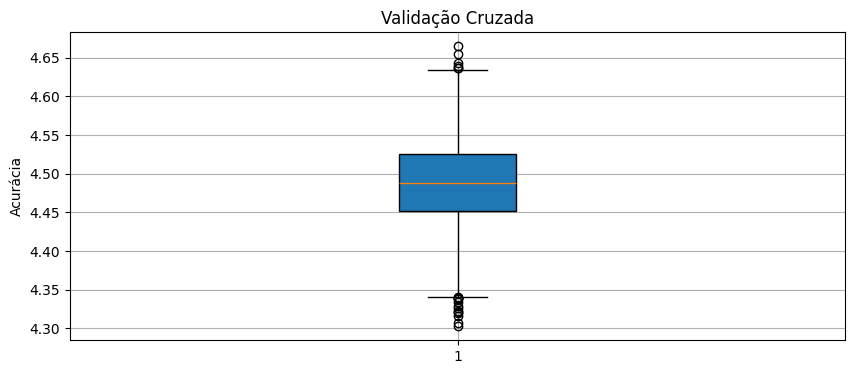

In [50]:
plt.figure(figsize=(10, 4))
plt.boxplot(df_texts_anon['entrpy_result_orig'], patch_artist=True)
plt.grid(True)
plt.title('Validação Cruzada')
plt.ylabel('Acurácia')
plt.show()


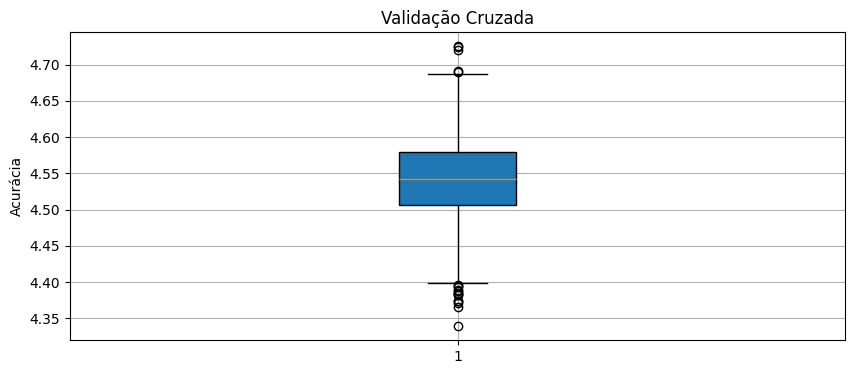

In [51]:
plt.figure(figsize=(10, 4))
plt.boxplot(df_texts_anon['entrpy_result_anon'], patch_artist=True)
plt.grid(True)
plt.title('Validação Cruzada')
plt.ylabel('Acurácia')
plt.show()


#### Teste Shapiro para verificação da distribuição

In [52]:
shapiro_orig = stats.shapiro(df_texts_anon["entrpy_result_orig"])
shapiro_anon = stats.shapiro(df_texts_anon["entrpy_result_anon"])
print(f"Teste de Shapiro-Wilk para entrpy_result_orig: p-valor={shapiro_orig.pvalue}")
print(f"Teste de Shapiro-Wilk para entrpy_result_anon: p-valor={shapiro_anon.pvalue}")

Teste de Shapiro-Wilk para entrpy_result_orig: p-valor=0.15647685388543003
Teste de Shapiro-Wilk para entrpy_result_anon: p-valor=0.07671552332886133


#### Teste de Wilcoxon - verificação da significancia

recomendação para utilização desse teste em casos que houvesse outliers - o que foi visto nas células acima

In [53]:
w_stat, p_value_w = stats.wilcoxon(df_texts_anon["entrpy_result_orig"], df_texts_anon["entrpy_result_anon"])

In [54]:
print(f"{w_stat} \n{p_value_w}")

1979.0 
2.859608270858311e-308


#### Teste T - para calculo de significancia também

In [55]:
t_stat, p_value_t = stats.ttest_rel(df_texts_anon["entrpy_result_orig"], df_texts_anon["entrpy_result_anon"])

In [56]:
print(f"{w_stat} \n{p_value_w}")

1979.0 
2.859608270858311e-308


#### pedi pro chatgpt me ajudar a interpretar ele criou isso aqui KKKKKKKKK

In [57]:
alpha = 0.05
if p_value_t < alpha:
    print("A diferença entre as entropias é estatisticamente significativa (Teste t).")
else:
    print("A diferença entre as entropias NÃO é estatisticamente significativa (Teste t).")

if p_value_w < alpha:
    print("A diferença entre as entropias é estatisticamente significativa (Teste de Wilcoxon).")
else:
    print("A diferença entre as entropias NÃO é estatisticamente significativa (Teste de Wilcoxon).")

A diferença entre as entropias é estatisticamente significativa (Teste t).
A diferença entre as entropias é estatisticamente significativa (Teste de Wilcoxon).


Media dos valores

In [58]:
df_texts_anon['entrpy_result_orig'].values.mean()

np.float64(4.48811474865559)

In [59]:
df_texts_anon['entrpy_result_anon'].values.mean()

np.float64(4.5420029427538)

In [60]:
np.std(df_texts_anon['entrpy_result_orig'].values)

np.float64(0.05642447566767289)

In [61]:
np.std(df_texts_anon['entrpy_result_anon'].values)

np.float64(0.05578468776192591)